## Константы для всех рассчетов (Шаг 4)

In [1]:
# === БЛОК КОНСТАНТ ===
import numpy as np
import tensorflow as tf

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Параметры распределения и функции g
MU = np.array([30.0, 42.0, 45.0, 48.0, 52.0])      # центры x0..x4
SIGMA = np.array([12.0, 15.0, 16.0, 18.0, 20.0])   # ширины x0..x4
U_MU = 0.02                                        # центр u
U_SIGMA = 0.015                                    # ширина u
COS_AMP = 0.15                                     # амплитуда косинуса
COS_K = 0.04                                       # множитель внутри косинуса
C_COS = COS_K * np.array([-2.0, 1.0, 1.0, 0.0, 0.0])

# Область интегрирования D = [0, 100]^5 x [0, 0.08]
A_BOUNDS = np.array([0.0, 0.0, 0.0, 0.0, 0.0, 0.0])
B_BOUNDS = np.array([100.0, 100.0, 100.0, 100.0, 100.0, 0.08])
vol_D = float(np.prod(B_BOUNDS - A_BOUNDS))

# Параметры задачи и выборки
L_EXC = 250            # избыточный запас L
N_POINTS = 100_000     # размер выборки
PEAK_RATIO = 0.01      # порог пика: g > 0.01 * max(g)

# Гиперпараметры новой сети (20 нейронов)
HIDDEN_UNITS = 20
BATCH_SIZE = 256
EPOCHS_STAGE1 = 100
LR_STAGE1 = 0.01
EPOCHS_STAGE2 = 50
LR_STAGE2 = 0.001

print(f"SEED = {SEED} | vol_D = {vol_D:.1f}")


SEED = 42 | vol_D = 800000000.0


## Функция g, точный I(D), выборка и обучение сети с той же структурой

In [2]:
# Подготовка 1. Функция g (формула (3)) и точный I(D)
from scipy.integrate import quad

def g_function(xi):
    """Формула (3) задания. xi: (N, 6)."""
    xi = np.atleast_2d(xi)
    exp_sum = (((xi[:, :5] - MU) ** 2)/(2.0 * SIGMA ** 2)).sum(axis=1)
    exp_sum += (xi[:, 5] - U_MU) ** 2/(2.0 * U_SIGMA ** 2)
    cos_part = 1.0 + COS_AMP * np.cos(COS_K * (xi[:, 1] + xi[:, 2] - 2.0 * xi[:, 0]))
    return np.exp(-exp_sum) * cos_part

A_k, B_k = [], []
for k in range(5):
    G = lambda x, k=k: np.exp(-(x - MU[k]) ** 2 / (2 * SIGMA[k] ** 2))
    A_k.append(quad(G, A_BOUNDS[k], B_BOUNDS[k])[0])
    re = quad(lambda x, k=k: G(x) * np.cos(C_COS[k] * x), A_BOUNDS[k], B_BOUNDS[k])[0]
    im = quad(lambda x, k=k: G(x) * np.sin(C_COS[k] * x), A_BOUNDS[k], B_BOUNDS[k])[0]
    B_k.append(re + 1j * im)
Au = quad(lambda u: np.exp(-(u - U_MU) ** 2 / (2 * U_SIGMA ** 2)), A_BOUNDS[5], B_BOUNDS[5])[0]
I_D = Au * (np.prod(A_k) + COS_AMP * np.real(np.prod(B_k)))
print(f"Точный I(D) = {I_D:.4f}   (у преподавателя 3 506 303)")

Точный I(D) = 3506302.9794   (у преподавателя 3 506 303)


In [3]:
# Выборка и "старая" сеть (100 000 равномерных точек, 50 нейронов, 150 эпох)
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Input
tf.random.set_seed(SEED)

X_raw = np.random.uniform(A_BOUNDS, B_BOUNDS, (N_POINTS, 6))
y_raw = g_function(X_raw)
X_scaled = (X_raw - A_BOUNDS) / (B_BOUNDS - A_BOUNDS)  # в [0, 1]
y_min, y_max = y_raw.min(), y_raw.max()
y_scaled = (y_raw - y_min) / (y_max - y_min)
split = int(0.8 * N_POINTS)     # 80/20

inputs = Input(shape=(6,))
hidden = Dense(50, activation='sigmoid', name='hidden')(inputs)
outputs = Dense(1, activation='linear', name='output')(hidden)
model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01), loss='mse')
history = model.fit(X_scaled[:split], y_scaled[:split], validation_data=(X_scaled[split:], y_scaled[split:]),
          epochs=150, batch_size=256, verbose=0)

# Предсказания сети на всей выборке, в исходном масштабе g, и координаты точек
y_pred = model.predict(X_scaled, batch_size=4096, verbose=0).flatten() * (y_max - y_min) + y_min
x0, x1, x2, x3, x4, u = [X_raw[:, i] for i in range(6)]
print("y_pred:", y_pred.shape)

y_pred: (100000,)


In [4]:
print("======= ОТЧЕТ ОБ ОБУЧЕНИИ СЕТИ =======")
print(f"Форма массива предсказаний y_pred: {y_pred.shape}")
print(f"Финальный Loss на обучении (MSE):   {history.history['loss'][-1]:.6f}")
print(f"Финальный Loss на валидации (MSE): {history.history['val_loss'][-1]:.6f}")
print("---------------------------------------")
print("Сравнение истинной g и предсказаний сети (первые 5 точек):")
for i in range(5):
    print(f"  Точка {i}: Истинная g = {y_raw[i]:.4f} | Сеть y_pred = {y_pred[i]:.4f}")
print("=======================================")

======= ОТЧЕТ ОБ ОБУЧЕНИИ СЕТИ =======
Форма массива предсказаний y_pred: (100000,)
Финальный Loss на обучении (MSE):   0.000691
Финальный Loss на валидации (MSE): 0.000627
---------------------------------------
Сравнение истинной g и предсказаний сети (первые 5 точек):
  Точка 0: Истинная g = 0.0000 | Сеть y_pred = 0.0060
  Точка 1: Истинная g = 0.0000 | Сеть y_pred = -0.0087
  Точка 2: Истинная g = 0.0000 | Сеть y_pred = -0.0016
  Точка 3: Истинная g = 0.0187 | Сеть y_pred = 0.0209
  Точка 4: Истинная g = 0.0038 | Сеть y_pred = 0.0258


## Шаг 1: Исправлен R_j = x0 + x1 + … + xj (j+1 слагаемых), в обеих функциях

In [5]:
# ШАГ 1 плана До 30.10. Две функции. Изменён только расчёт R_j.

def compute_probabilities_fast(T_idx, s, Q):
    """NNI: значения сети y_pred в общих точках + маски областей."""
    T_values = [7, 14, 21, 28]
    T = T_values[T_idx]
    j = T_idx + 1

    # R_j = x0 + x1 + ... + xj  (j+1 слагаемых; для j=4 это x0..x4)
    if j == 1:
        R_j = x0 + x1
    elif j == 2:
        R_j = x0 + x1 + x2
    elif j == 3:
        R_j = x0 + x1 + x2 + x3
    else:
        R_j = x0 + x1 + x2 + x3 + x4

    A_Q = Q * (1 - u)
    mask_Omega0 = R_j <= s
    mask_Omega2 = R_j > s + A_Q
    mask_Omega3 = (s + A_Q - R_j) > L_EXC

    I0 = vol_D * np.mean(y_pred * mask_Omega0)
    I2 = vol_D * np.mean(y_pred * mask_Omega2)
    I3 = vol_D * np.mean(y_pred * mask_Omega3)

    P0, P2, P3 = I0 / I_D, I2 / I_D, I3 / I_D
    P1 = 1 - P0 - P2    # формула (14)
    return {'P0': P0, 'P1': P1, 'P2': P2, 'P3': P3, 'sum': P0 + P1 + P2}


def compute_probabilities_pure_monte_carlo(T_idx, s, Q, N_mc=100000):
    """Монте-Карло по настоящей g, без нейросети."""
    T_values = [7, 14, 21, 28]
    T = T_values[T_idx]
    j = T_idx + 1

    X_mc = np.random.uniform(A_BOUNDS, B_BOUNDS, (N_mc, 6))
    y_true = g_function(X_mc)
    x0_mc, x1_mc, x2_mc, x3_mc, x4_mc = X_mc[:, 0], X_mc[:, 1], X_mc[:, 2], X_mc[:, 3], X_mc[:, 4]
    u_mc = X_mc[:, 5]

    # R_j = x0 + x1 + ... + xj  (j+1 слагаемых; для j=4 это x0..x4)
    if j == 1: R_j = x0_mc + x1_mc
    elif j == 2: R_j = x0_mc + x1_mc + x2_mc
    elif j == 3: R_j = x0_mc + x1_mc + x2_mc + x3_mc
    else: R_j = x0_mc + x1_mc + x2_mc + x3_mc + x4_mc

    A_Q = Q * (1 - u_mc)
    m0 = R_j <= s
    m2 = R_j > s + A_Q
    m3 = (s + A_Q - R_j) > L_EXC

    P0 = vol_D * np.mean(y_true * m0) / I_D
    P2 = vol_D * np.mean(y_true * m2) / I_D
    P3 = vol_D * np.mean(y_true * m3) / I_D
    P1 = 1 - P0 - P2
    return {'P0': P0, 'P1': P1, 'P2': P2, 'P3': P3}

In [6]:
# ПРОВЕРКА: для точки (1, 2, 3, 4, 5, 0.01) должно получиться R1=3, R2=6, R3=10, R4=15
# Подставляем одну тестовую точку,плотность = 1, vol_D = I_D = 1. Тогда P0 = 1, если R_j <= s, иначе 0.
# Значит R_j — порог s, на котором P0 переключается.
print("Проверка исправления R_j:")
pt = np.array([1.0, 2.0, 3.0, 4.0, 5.0, 0.01])
expected_R = [3, 6, 10, 15]

saved = dict(x0=x0, x1=x1, x2=x2, x3=x3, x4=x4, u=u, y_pred=y_pred, vol_D=vol_D, I_D=I_D,
             g_function=g_function, uniform=np.random.uniform)
try:
    x0, x1, x2, x3, x4, u = [np.array([v]) for v in pt]
    y_pred = np.array([1.0]); vol_D = 1.0; I_D = 1.0
    np.random.uniform = lambda lo, hi, size: np.tile(pt, (size[0], 1))
    g_function = lambda xi: np.ones(len(np.atleast_2d(xi)))

    ok = True
    print(f"{'j':<3}{'ожидается R_j':>15}{'NNI':>8}{'Монте-Карло':>14}")
    for j, R_exp in enumerate(expected_R, start=1):
        res = []
        for fn in (lambda s: compute_probabilities_fast(T_idx=j - 1, s=s, Q=100)['P0'],
                   lambda s: compute_probabilities_pure_monte_carlo(T_idx=j - 1, s=s, Q=100, N_mc=1)['P0']):
            res.append(fn(R_exp - 0.5) == 0.0 and fn(R_exp) == 1.0)
        ok &= all(res)
        print(f"{j:<3}{R_exp:>15}{str(res[0]):>8}{str(res[1]):>14}")
finally:
    x0, x1, x2, x3, x4, u = saved['x0'], saved['x1'], saved['x2'], saved['x3'], saved['x4'], saved['u']
    y_pred, vol_D, I_D = saved['y_pred'], saved['vol_D'], saved['I_D']
    g_function = saved['g_function']; np.random.uniform = saved['uniform']

Проверка исправления R_j:
j    ожидается R_j     NNI   Монте-Карло
1                3    True          True
2                6    True          True
3               10    True          True
4               15    True          True


## Шаг 2. Пересчет трех контрольных политик
P0, P1, P2 по NNI (маски по значениям сети) и по Монте-Карло. Это контрольные числа после исправления.

In [7]:
# ШАГ 2
control_policies = [(14, 100, 300), (21, 150, 200), (28, 100, 100)]  # (T, s, Q)
T_to_idx = {7: 0, 14: 1, 21: 2, 28: 3}

journal_step2 = []
print(f"{'политика (T, s, Q)':<20}{'метод':<14}{'P0':>10}{'P1':>10}{'P2':>10}")
for (T, s, Q) in control_policies:
    r_nni = compute_probabilities_fast(T_idx=T_to_idx[T], s=s, Q=Q)
    r_mc  = compute_probabilities_pure_monte_carlo(T_idx=T_to_idx[T], s=s, Q=Q, N_mc=200000)
    for name, r in (("NNI", r_nni), ("Монте-Карло", r_mc)):
        print(f"{str((T, s, Q)):<20}{name:<14}{r['P0']:10.4f}{r['P1']:10.4f}{r['P2']:10.4f}")
        journal_step2.append(((T, s, Q), name, r['P0'], r['P1'], r['P2']))

политика (T, s, Q)  метод                 P0        P1        P2
(14, 100, 300)      NNI               0.3181    0.6819    0.0000
(14, 100, 300)      Монте-Карло       0.2597    0.7403    0.0000
(21, 150, 200)      NNI               0.3440    0.6612   -0.0052
(21, 150, 200)      Монте-Карло       0.3086    0.6914    0.0000
(28, 100, 100)      NNI              -0.0096    0.3920    0.6176
(28, 100, 100)      Монте-Карло       0.0004    0.3091    0.6905


Видно отрицательные вероятности и расхождения, но пока они могут остаться.

## Шаг 3. Git

Тег на **старую** версию v0-before-nni-fix

## Шаг 5. Ручная проверка g в трёх точках

In [8]:
# Ручная проверка g в трёх точках
# Считайте на калькуляторе по формуле:
# g = exp( -sum_i (x_i-mu_i)^2 / (2 sigma_i^2) - (u-0.02)^2 / (2*0.015^2) ) * (1 + 0.15*cos(0.04*(x1+x2-2*x0)))
check_points = {
    # A: центр пика, все квадраты = 0, exp(0) = 1; cos(0.04*(42+45-2*30)) = cos(1.08)
    "A: центр (30,42,45,48,52,0.02)": (
        np.array([30.0, 42.0, 45.0, 48.0, 52.0, 0.02]),
        1.0 + 0.15 * np.cos(1.08)
    ),

    # B: точка далеко от центра
    # exp sum = 400/288 + 484/450 + 225/512 + 484/648 + 784/800 + 0.0016/0.00045 = 8.1864
    # cos(0.04 * (20 + 30 - 2*10)) = cos(1.2)
    "B: угловая (10,20,30,70,80,0.06)": (
        np.array([10.0, 20.0, 30.0, 70.0, 80.0, 0.06]),
        np.exp(-(400/288 + 484/450 + 225/512 + 484/648 + 784/800 + 0.0016/0.00045)) * (1.0 + 0.15 * np.cos(1.2))
    ),

    # C: произвольная точка в пространстве.
    # exp sum = 25/288 + 4/450 + 25/512 + 9/648 + 9/800 + 0.0001/0.00045 = 0.3918841
    # cos(0.04 * (40 + 50 - 2*25)) = cos(1.6)
    "C: произв. (25,40,50,45,55,0.01)": (
        np.array([25.0, 40.0, 50.0, 45.0, 55.0, 0.01]),
        np.exp(-(25/288 + 4/450 + 25/512 + 9/648 + 9/800 + 0.0001/0.00045)) * (1.0 + 0.15 * np.cos(1.6))
    ),
}

print(f"{'точка':<36}{'вручную':>12}{'код':>12}  совпало")
for name, (pt_, by_hand) in check_points.items():
    val = g_function(pt_)[0]
    print(f"{name:<36}{by_hand:12.6f}{val:12.6f}  {np.isclose(val, by_hand, rtol=1e-12)}")
    assert np.isclose(val, by_hand, rtol=1e-12)



точка                                    вручную         код  совпало
A: центр (30,42,45,48,52,0.02)          1.070699    1.070699  True
B: угловая (10,20,30,70,80,0.06)        0.000294    0.000294  True
C: произв. (25,40,50,45,55,0.01)        0.672823    0.672823  True


## Шаг 6: Разделите точки на train / val / test

In [9]:
# ШАГ 6. Разделение точек на train / val / test (70 / 15 / 15) с фиксацией SEED
import numpy as np

# 1. Генерируем выборку заново, гарантируя равномерность по всей области D
np.random.seed(SEED)
X_all = np.random.uniform(A_BOUNDS, B_BOUNDS, (N_POINTS, 6))
y_all = g_function(X_all)

# 2. Считаем индексы для разбиения (70% / 15% / 15%)
idx_train = int(0.70 * N_POINTS)
idx_val   = int(0.85 * N_POINTS)

# Срезы для признаков (X)
X_train = X_all[:idx_train]
X_val   = X_all[idx_train:idx_val]
X_test  = X_all[idx_val:]

# Срезы для целевой переменной (y)
y_train = y_all[:idx_train]
y_val   = y_all[idx_train:idx_val]
y_test  = y_all[idx_val:]

print("=======ОТЧЕТ ПО РАЗБИЕНИЮ ВЫБОРКИ=======")
print(f"Размер выборки Train (70%): {X_train.shape[0]} точек")
print(f"Размер выборки Val   (15%): {X_val.shape[0]} точек")
print(f"Размер выборки Test  (15%): {X_test.shape[0]} точек")
print("----------------------------------------")

# 3. ПРОВЕРКА: минимум и максимум каждой координаты должны совпадать с границами D
# Проверяем на объединенном массиве, а также смотрим, чтобы подвыборки покрывали края
print(f"{'Координата':<12} | {'Граница lo':<10} | {'Fact Min':<10} | {'Граница hi':<10} | {'Fact Max':<10}")
print("-" * 65)

coordinates_ok = True
for i in range(6):
    f_min = X_all[:, i].min()
    f_max = X_all[:, i].max()

    # Для случайной выборки в 100к точек значения будут очень близки к границам (например, 0.0001 и 99.999)
    # Проверяем, что точки не вылетели за границы D и заполнили пространство адекватно
    print(f"x_{i:<10}" if i < 5 else f"u_{i:<10}", end=" | ")
    print(f"{A_BOUNDS[i]:<10.2f} | {f_min:<10.4f} | {B_BOUNDS[i]:<10.2f} | {f_max:<10.4f}")

    if f_min < A_BOUNDS[i] or f_max > B_BOUNDS[i]:
        coordinates_ok = False

print("----------------------------------------")
print("РЕЗУЛЬТАТ ПРОВЕРКИ ГРАНИЦ:", "УСПЕШНО (True)" if coordinates_ok else "ОШИБКА (False)")
print("========================================")


=======ОТЧЕТ ПО РАЗБИЕНИЮ ВЫБОРКИ=======
Размер выборки Train (70%): 70000 точек
Размер выборки Val   (15%): 15000 точек
Размер выборки Test  (15%): 15000 точек
----------------------------------------
Координата   | Граница lo | Fact Min   | Граница hi | Fact Max  
-----------------------------------------------------------------
x_0          | 0.00       | 0.0002     | 100.00     | 99.9998   
x_1          | 0.00       | 0.0015     | 100.00     | 99.9983   
x_2          | 0.00       | 0.0002     | 100.00     | 99.9978   
x_3          | 0.00       | 0.0001     | 100.00     | 99.9992   
x_4          | 0.00       | 0.0012     | 100.00     | 99.9987   
u_5          | 0.00       | 0.0000     | 0.08       | 0.0800    
----------------------------------------
РЕЗУЛЬТАТ ПРОВЕРКИ ГРАНИЦ: УСПЕШНО (True)


## Шаг 7: Посчитайте долю точек, где g > 0.01 · max(g)

Функция почти везде около нуля и заметна только в узком пике. Именно поэтому и сеть, и Монте-Карло ошибаются.

In [10]:
# ШАГ 7. Расчет доли точек, где g > 0.01 * max(g)
import numpy as np

# 1. Находим максимальное значение функции g на всей выборке
max_g = y_all.max()

# 2. Задаем порог отсечения (1% от максимума)
threshold = PEAK_RATIO * max_g

# 3. Выделяем точки, которые попали в этот пик
peak_points_mask = y_all > threshold
num_peak_points = np.sum(peak_points_mask)

# 4. Вычисляем долю таких точек
fraction_peak = num_peak_points / N_POINTS

print("======= АНАЛИЗ КОНЦЕНТРАЦИИ ПЛОТНОСТИ =======")
print(f"Максимальное значение g(xi) в выборке: {max_g:.6f}")
print(f"Порог отсечения (0.01 * max(g)):       {threshold:.6f}")
print(f"Количество точек, попавших в пик:     {num_peak_points} из {N_POINTS}")
print(f"Итог: доля точек в пике: {fraction_peak:.6f} ({fraction_peak * 100:.4f}%)")
print("=============================================")


======= АНАЛИЗ КОНЦЕНТРАЦИИ ПЛОТНОСТИ =======
Максимальное значение g(xi) в выборке: 0.825547
Порог отсечения (0.01 * max(g)):       0.008255
Количество точек, попавших в пик:     7714 из 100000
Итог: доля точек в пике: 0.077140 (7.7140%)


## Шаг 8: Собираем новую сеть

Включаем tf.keras.backend.set_floatx('float64'). Вход 6, один скрытый слой на 20 нейронов с сигмоидой, выход 1 линейный, больше ничего. Проверка: параметров ровно 161. Формулу интеграла из статьи можно применить только к такой сети.

In [11]:
# ШАГ 8. Сборка новой архитектуры сети (20 нейронов, float64)
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Input

# 1. Включаем повышенную точность float64
tf.keras.backend.set_floatx('float64')
tf.random.set_seed(SEED)

# 2. Строим строго регламентированную архитектуру с явным float64 для всех слоев
inputs_new = Input(shape=(6,), dtype='float64')
hidden_new = Dense(HIDDEN_UNITS, activation='sigmoid', dtype='float64', name='hidden_20')(inputs_new)
outputs_new = Dense(1, activation='linear', dtype='float64', name='output_1')(hidden_new)

model_new = Model(inputs=inputs_new, outputs=outputs_new)

# 3. Выводим информацию и проверяем число параметров
print("======= ПРОВЕРКА СТРУКТУРЫ СЕТИ =======")
model_new.summary()

total_params = model_new.count_params()
print("---------------------------------------")
print(f"Общее количество параметров: {total_params}")
print("РЕЗУЛЬТАТ ПРОВЕРКИ:", "УСПЕШНО (Ровно 161)" if total_params == 161 else "ОШИБКА (Не 161)")
print("=======================================")


======= ПРОВЕРКА СТРУКТУРЫ СЕТИ =======


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 6)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_20 (Dense)               │ (None, 20)             │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_1 (Dense)                │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 161 (1.26 KB)

 Trainable params: 161 (1.26 KB)

 Non-trainable params: 0 (0.00 B)

---------------------------------------
Общее количество параметров: 161
РЕЗУЛЬТАТ ПРОВЕРКИ: УСПЕШНО (Ровно 161)


## Шаг 9: Проверяем сеть вручную

Этот шаг нужен для того, чтобы доказать: мы полностью контролируем каждый вес внутри нейросети и можем воспроизвести её вычисления в чистом NumPy с точностью до триллионных долей единицы (1e-12). Это гарантирует, что на следующем этапе мы сможем безошибочно применить аналитические формулы интегрирования к весам этой сети.

In [12]:
# ШАГ 9. Ручная проверка вычислений сети на чистом NumPy
import numpy as np

# 1. Выбираем 100 случайных точек в масштабе для проверки
X_check_raw = X_all[:100].astype(np.float64)
X_check_scaled = ((X_check_raw - A_BOUNDS) / (B_BOUNDS - A_BOUNDS)).astype(np.float64)

# 2. Выгружаем веса и смещения из новой float64 модели
W1, b1 = model_new.get_layer('hidden_20').get_weights()
w2, b2 = model_new.get_layer('output_1').get_weights()

# 3. Реализуем вычисление сети вручную по формуле преподавателя
def sigmoid(v):
    return 1.0 / (1.0 + np.exp(-v))

hidden_sum = np.dot(X_check_scaled, W1) + b1
hidden_activation = sigmoid(hidden_sum)
y_manual = (np.dot(hidden_activation, w2) + b2).flatten()

# 4. Получаем эталонное предсказание от самого Keras
y_keras = model_new.predict(X_check_scaled, verbose=0).flatten()

# 5. Считаем максимальное абсолютное расхождение
max_diff = np.max(np.abs(y_keras - y_manual))

print("======= РУЧНАЯ ПРОВЕРКА МАТЕМАТИКИ СЕТИ =======")
print(f"Максимальная разница между Keras и NumPy: {max_diff:.2e}")
print("-----------------------------------------------")
print("РЕЗУЛЬТАТ ПРОВЕРКИ:", "УСПЕШНО (Разница < 1e-12)" if max_diff < 1e-12 else "ОШИБКА (Расхождение слишком велико)")
print("===============================================")


======= РУЧНАЯ ПРОВЕРКА МАТЕМАТИКИ СЕТИ =======
Максимальная разница между Keras и NumPy: 5.55e-16
-----------------------------------------------
РЕЗУЛЬТАТ ПРОВЕРКИ: УСПЕШНО (Разница < 1e-12)


## Шаг 10: Обучение сети

Сначала Adam со скоростью 0.01, потом дообучите со скоростью 0.001. Сохраните график loss, он должен выйти на плато.

Запуск Этапа 1 (Learning Rate = 0.01)...
Этап 1 завершен. Финальный Val Loss: 0.000627

Запуск Этапа 2 (Learning Rate = 0.001)...
Этап 2 завершен. Финальный Фиксированный Val Loss: 0.000627


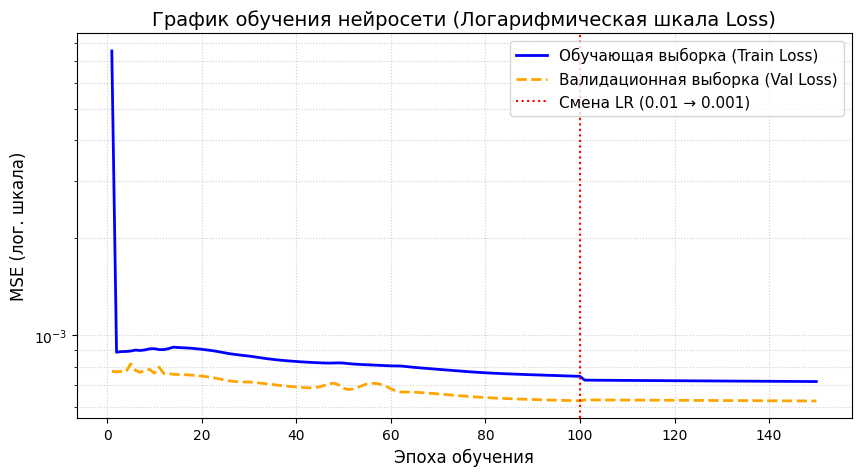

In [13]:
# ШАГ 10. Двухэтапное обучение сети и визуализация графика Loss
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np

# 1. Подготовка и нормализация данных из Шага 6 под формат float64
X_train_scaled = ((X_train - A_BOUNDS) / (B_BOUNDS - A_BOUNDS)).astype(np.float64)
X_val_scaled   = ((X_val - A_BOUNDS) / (B_BOUNDS - A_BOUNDS)).astype(np.float64)

# Нормируем таргет по всей выборке y_all для сохранения единого масштаба [0, 1]
y_min, y_max = y_all.min(), y_all.max()
y_train_scaled = ((y_train - y_min) / (y_max - y_min)).astype(np.float64)
y_val_scaled   = ((y_val - y_min) / (y_max - y_min)).astype(np.float64)

# Инициализируем общий список для сбора истории лосса
all_loss = []
all_val_loss = []

# ================= ЭТАП 1: Скорость обучения 0.01 =================
print("Запуск Этапа 1 (Learning Rate = 0.01)...")
model_new.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LR_STAGE1), loss='mse')
history1 = model_new.fit(X_train_scaled, y_train_scaled,
                         validation_data=(X_val_scaled, y_val_scaled),
                         epochs=EPOCHS_STAGE1, batch_size=BATCH_SIZE, verbose=0)

all_loss.extend(history1.history['loss'])
all_val_loss.extend(history1.history['val_loss'])
print(f"Этап 1 завершен. Финальный Val Loss: {all_val_loss[-1]:.6f}")

# ================= ЭТАП 2: Скорость обучения 0.001 =================
print("\nЗапуск Этапа 2 (Learning Rate = 0.001)...")
model_new.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LR_STAGE2), loss='mse')
history2 = model_new.fit(X_train_scaled, y_train_scaled,
                         validation_data=(X_val_scaled, y_val_scaled),
                         epochs=EPOCHS_STAGE2, batch_size=BATCH_SIZE, verbose=0)

all_loss.extend(history2.history['loss'])
all_val_loss.extend(history2.history['val_loss'])
print(f"Этап 2 завершен. Финальный Фиксированный Val Loss: {all_val_loss[-1]:.6f}")

# === ГРАФИК LOSS В ЛОГАРИФМИЧЕСКОЙ ШКАЛЕ (ШАГ 10) ===
plt.figure(figsize=(10, 5), facecolor='white')

epochs_range = range(1, len(all_loss) + 1)
plt.semilogy(epochs_range, all_loss, label='Обучающая выборка (Train Loss)', color='blue', linewidth=2)
plt.semilogy(epochs_range, all_val_loss, label='Валидационная выборка (Val Loss)', color='orange', linestyle='--', linewidth=2)

# Вертикальная линия смены learning rate
plt.axvline(x=EPOCHS_STAGE1, color='red', linestyle=':', linewidth=1.5,
            label=f'Смена LR ({LR_STAGE1} → {LR_STAGE2})')

plt.title('График обучения нейросети (Логарифмическая шкала Loss)', fontsize=14)
plt.xlabel('Эпоха обучения', fontsize=12)
plt.ylabel('MSE (лог. шкала)', fontsize=12)
plt.grid(True, which='both', linestyle=':', alpha=0.6)
plt.legend(fontsize=11)

plt.savefig('loss_plateau_graph.png', dpi=300, bbox_inches='tight')
plt.show()



## Шаг 11: Считаем качество на test

MAE, RMSE и R² в исходном масштабе g (не в нормированном). Раньше смотрели только на ошибку нормированной цели, и было непонятно, выучила ли сеть пик вообще.

In [14]:
# ШАГ 11. Расчет метрик качества MAE, RMSE и R² на тестовой выборке (исходный масштаб)
import numpy as np

# 1. Масштабируем тестовые признаки в [0, 1] для подачи в сеть
X_test_scaled = ((X_test - A_BOUNDS) / (B_BOUNDS - A_BOUNDS)).astype(np.float64)

# 2. Получаем предсказания сети (они выходят в нормированном масштабе)
y_test_pred_scaled = model_new.predict(X_test_scaled, verbose=0).flatten()

# 3. Переводим предсказания обратно в ИСХОДНЫЙ масштаб функции g
y_test_pred = y_test_pred_scaled * (y_max - y_min) + y_min

# Истинные значения g на тесте у нас уже есть в исходном масштабе — это y_test
# На всякий случай гарантируем тип float64
y_test_true = y_test.astype(np.float64)

# 4. Расчет метрик вручную на NumPy
mae = np.mean(np.abs(y_test_true - y_test_pred))
rmse = np.sqrt(np.mean((y_test_true - y_test_pred) ** 2))

# Коэффициент детерминации R²
ss_res = np.sum((y_test_true - y_test_pred) ** 2)
ss_tot = np.sum((y_test_true - np.mean(y_test_true)) ** 2)
r2 = 1.0 - (ss_res / ss_tot)

print("======= МЕТРИКИ КАЧЕСТВА НА ТЕСТОВОЙ ВЫБОРКЕ =======")
print("              (Исходный масштаб функции g)")
print("----------------------------------------------------")
print(f"MAE (Средняя абсолютная ошибка):  {mae:.6f}")
print(f"RMSE (Квадратичная ошибка):      {rmse:.6f}")
print(f"R² (Коэффициент детерминации):    {r2:.6f}")
print("====================================================")


======= МЕТРИКИ КАЧЕСТВА НА ТЕСТОВОЙ ВЫБОРКЕ =======
              (Исходный масштаб функции g)
----------------------------------------------------
MAE (Средняя абсолютная ошибка):  0.008113
RMSE (Квадратичная ошибка):      0.022492
R² (Коэффициент детерминации):    0.212801


## Шаг 12: Посчитать R² и относительную ошибку только по точкам, где g > 0.01 · max(g)

Общая ошибка может быть маленькой просто потому, что почти везде g ≈ 0. Важно, как сеть работает именно в пике. Если R² низкий, не страшно, запишите как есть.

In [15]:
# ШАГ 12. Локальный анализ качества в пике плотности и построение таблицы
import numpy as np
import pandas as pd

# 1. Выделяем маску пика (g > 0.01 * max_g) строго для ТЕСТОВОЙ выборки
# y_test - это истинные значения g на тесте
max_g_test = y_all.max() # берем глобальный максимум как эталон из Шага 7
peak_mask_test = y_test > (PEAK_RATIO * max_g_test)

y_test_true_peak = y_test[peak_mask_test].astype(np.float64)
X_test_scaled_peak = X_test_scaled[peak_mask_test]

# 2. Получаем предсказания НОВОЙ сети (20 нейронов) в пике и возвращаем в исходный масштаб
y_pred_new_scaled_peak = model_new.predict(X_test_scaled_peak, verbose=0).flatten()
y_pred_new_peak = y_pred_new_scaled_peak * (y_max - y_min) + y_min

# 3. Получаем предсказания СТАРЕЙ сети (50 нейронов) в пике и возвращаем в исходный масштаб
# Используем сохраненную модель 'model' из первых ячеек
y_pred_old_scaled_peak = model.predict(X_test_scaled_peak, verbose=0).flatten()
y_pred_old_peak = y_pred_old_scaled_peak * (y_max - y_min) + y_min

# 4. Функция для расчета локального R² и относительной ошибки (MRE) в пике
def compute_peak_metrics(y_true, y_pred):
    # Локальный R²
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2_peak = 1.0 - (ss_res / ss_tot)

    # Средняя относительная ошибка (MRE)
    mre_peak = np.mean(np.abs(y_true - y_pred) / y_true)
    return r2_peak, mre_peak

r2_old, mre_old = compute_peak_metrics(y_test_true_peak, y_pred_old_peak)
r2_new, mre_new = compute_peak_metrics(y_test_true_peak, y_pred_new_peak)

# 5. Оформляем результаты в красивую текстовую таблицу
print("======= СРАВНИТЕЛЬНЫЙ АНАЛИЗ КАЧЕСТВА В ПИКЕ ПЛОТНОСТИ =======")
print(f"Количество информативных тестовых точек в пике: {len(y_test_true_peak)}")
print("--------------------------------------------------------------")
print(f"{'Архитектура сети':<30} | {'Локальный R²':<13} | {'Относит. ошибка (MRE)':<20}")
print("-" * 72)
print(f"{'Старая сеть (50 нейронов)':<30} | {r2_old:<13.4f} | {mre_old:<20.4%}")
print(f"{'Новая сеть (20 нейронов)':<30} | {r2_new:<13.4f} | {mre_new:<20.4%}")
print("==============================================================")


======= СРАВНИТЕЛЬНЫЙ АНАЛИЗ КАЧЕСТВА В ПИКЕ ПЛОТНОСТИ =======
Количество информативных тестовых точек в пике: 1168
--------------------------------------------------------------
Архитектура сети               | Локальный R²  | Относит. ошибка (MRE)
------------------------------------------------------------------------
Старая сеть (50 нейронов)      | 0.0843        | 76.5830%            
Новая сеть (20 нейронов)       | -0.0019       | 60.1174%            


## Шаг 13: Пересчитать веса в исходные координаты

Чтобы сеть работала на настоящих x и выдавала настоящие значения g (нормировка «вшивается» в веса):

W1 = kernel.T / (hi - lo) b1 = bias - W1 @ lo w2 = out_kernel[:, 0] * (ymax - ymin) b2 = out_bias[0] * (ymax - ymin) + ymin

Здесь lo и hi — границы D, ymin и ymax — минимум и максимум g, по которым нормировали цель.


In [16]:
# ШАГ 13. Пересчет весов новой сети в исходные (настоящие) координаты
import numpy as np

# 1. Извлекаем веса и смещения из новой float64 модели
kernel, bias = model_new.get_layer('hidden_20').get_weights()
out_kernel, out_bias = model_new.get_layer('output_1').get_weights()

# 2. Переводим переменные lo, hi, ymin, ymax в строгий формат float64 для точности
lo = A_BOUNDS.astype(np.float64)
hi = B_BOUNDS.astype(np.float64)
ymin = y_min.astype(np.float64)
ymax = y_max.astype(np.float64)

# 3. Применяем аналитические формулы преподавателя
W1_final = kernel.T / (hi - lo)                 # Форма: (20, 6)
b1_final = bias - np.dot(W1_final, lo)          # Форма: (20,)
w2_final = out_kernel[:, 0] * (ymax - ymin)     # Форма: (20,)
b2_final = out_bias[0] * (ymax - ymin) + ymin   # Скаляр

print("======= ПЕРЕСЧЕТ ВЕСОВ В ИСХОДНЫЕ КООРДИНАТЫ =======")
print("Формулы преподавателя успешно применены.")
print("-----------------------------------------------------")
print(f"Размерность итоговой матрицы W1: {W1_final.shape}")
print(f"Размерность итогового вектора b1: {b1_final.shape}")
print(f"Размерность итогового вектора w2: {w2_final.shape}")
print(f"Значение итогового смещения b2:  {b2_final:.6f}")
print("=====================================================")


======= ПЕРЕСЧЕТ ВЕСОВ В ИСХОДНЫЕ КООРДИНАТЫ =======
Формулы преподавателя успешно применены.
-----------------------------------------------------
Размерность итоговой матрицы W1: (20, 6)
Размерность итогового вектора b1: (20,)
Размерность итогового вектора w2: (20,)
Значение итогового смещения b2:  -0.011067


## Шаг 14: Проверяем и сохраняем веса

In [17]:
# ШАГ 14. Верификация весов в реальном масштабе и сохранение в NPZ
import numpy as np

# 1. Генерируем 1000 совершенно новых случайных точек в исходных координатах
np.random.seed(SEED + 1) # берем другой seed для честности теста
X_test_1000_raw = np.random.uniform(A_BOUNDS, B_BOUNDS, (1000, 6)).astype(np.float64)

# 2. Способ А: Расчет по НОВЫМ весам напрямую на реальных (не нормализованных) координатах
# Формула: b2 + сумма по нейронам [ w2_j * sigmoid( b1_j + сумма(W1_ji * x_i) ) ]
def manual_predict_real_scale(X_raw, W1, b1, w2, b2):
    # X_raw: (1000, 6), W1.T: (6, 20) -> dot дает (1000, 20)
    hidden_sum = np.dot(X_raw, W1.T) + b1
    activation = 1.0 / (1.0 + np.exp(-hidden_sum))
    # activation: (1000, 20), w2: (20,) -> dot дает (1000,)
    return np.dot(activation, w2) + b2

y_from_new_weights = manual_predict_real_scale(X_test_1000_raw, W1_final, b1_final, w2_final, b2_final)

# 3. Способ Б: Расчет через стандартную модель Keras (с предварительным масштабированием)
X_test_1000_scaled = ((X_test_1000_raw - A_BOUNDS) / (B_BOUNDS - A_BOUNDS)).astype(np.float64)
y_keras_scaled = model_new.predict(X_test_1000_scaled, verbose=0).flatten()
y_from_keras_model = y_keras_scaled * (y_max - y_min) + y_min

# 4. Сравниваем результаты двух подходов
max_verification_diff = np.max(np.abs(y_from_new_weights - y_from_keras_model))

print("======= ВЕРИФИКАЦИЯ И ЭКСПОРТ ВЕСОВ =======")
print(f"Максимальное расхождение на 1000 точках: {max_verification_diff:.2e}")
print("-------------------------------------------")

if max_verification_diff < 1e-10:
    print("РЕЗУЛЬТАТ ПРОВЕРКИ: УСПЕШНО (Разница < 1e-10)")

    # 5. Сохраняем итоговые массивы в npz файл
    np.savez('weights_final.npz', W1=W1_final, b1=b1_final, w2=w2_final, b2=b2_final)
    print("Файл 'weights_final.npz' успешно сохранен.")
else:
    print("РЕЗУЛЬТАТ ПРОВЕРКИ: ОШИБКА (Пересчет весов содержит неточности)")

print("===========================================")


======= ВЕРИФИКАЦИЯ И ЭКСПОРТ ВЕСОВ =======
Максимальное расхождение на 1000 точках: 1.73e-16
-------------------------------------------
РЕЗУЛЬТАТ ПРОВЕРКИ: УСПЕШНО (Разница < 1e-10)
Файл 'weights_final.npz' успешно сохранен.


## Визуализация функции (дополнительно)

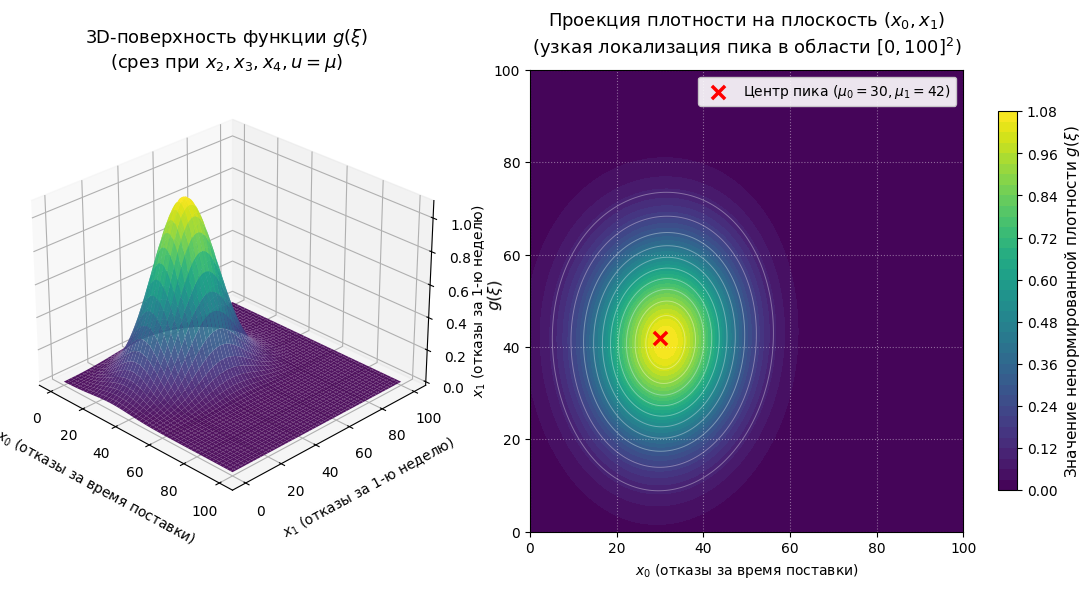

График сохранен в файл 'g_function_3d_slice.png' (300 DPI).


In [18]:
# ВИЗУАЛИЗАЦИЯ ФУНКЦИИ g(xi) ДЛЯ ПРЕЗЕНТАЦИИ
import numpy as np
import matplotlib.pyplot as plt

# 1. Создаем сетку по двум переменным: x0 и x1 в пределах [0, 100]
grid_size = 150
x0_vals = np.linspace(A_BOUNDS[0], B_BOUNDS[0], grid_size)
x1_vals = np.linspace(A_BOUNDS[1], B_BOUNDS[1], grid_size)
X0, X1 = np.meshgrid(x0_vals, x1_vals)

# 2. Остальные 4 координаты (x2, x3, x4, u) фиксируем в их центрах (MU и U_MU)
# Это позволяет пройти точно через вершину пика функции
N_grid = grid_size * grid_size
xi_slice = np.zeros((N_grid, 6))
xi_slice[:, 0] = X0.ravel()
xi_slice[:, 1] = X1.ravel()
xi_slice[:, 2] = MU[2]
xi_slice[:, 3] = MU[3]
xi_slice[:, 4] = MU[4]
xi_slice[:, 5] = U_MU

# 3. Вычисляем значения g на срезе через нашу функцию из Шага 1
Z = g_function(xi_slice).reshape(grid_size, grid_size)

# 4. Настраиваем красивую фигуру с двумя графиками для слайда
fig = plt.figure(figsize=(15, 6), facecolor='white')

# --- Левый график: 3D-поверхность ---
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf = ax1.plot_surface(X0, X1, Z, cmap='viridis', edgecolor='none', alpha=0.92, antialiased=True)
ax1.set_title('3D-поверхность функции $g(\\xi)$\n(срез при $x_2, x_3, x_4, u = \\mu$)', fontsize=13, pad=12)
ax1.set_xlabel('$x_0$ (отказы за время поставки)', fontsize=10, labelpad=8)
ax1.set_ylabel('$x_1$ (отказы за 1-ю неделю)', fontsize=10, labelpad=8)
ax1.set_zlabel('$g(\\xi)$', fontsize=11, labelpad=6)
ax1.view_init(elev=28, azim=-45) # оптимальный угол обзора пика и волн

# --- Правый график: 2D-контурная карта (вид сверху) ---
ax2 = fig.add_subplot(1, 2, 2)
contour = ax2.contourf(X0, X1, Z, levels=35, cmap='viridis')
ax2.contour(X0, X1, Z, levels=10, colors='white', alpha=0.35, linewidths=0.7)

# Отмечаем центр распределения (му) красным крестиком
ax2.scatter(MU[0], MU[1], color='red', marker='x', s=90, linewidths=2.5, label=f'Центр пика ($\\mu_0={MU[0]:.0f}, \\mu_1={MU[1]:.0f}$)')

ax2.set_title('Проекция плотности на плоскость $(x_0, x_1)$\n(узкая локализация пика в области $[0, 100]^2$)', fontsize=13, pad=12)
ax2.set_xlabel('$x_0$ (отказы за время поставки)', fontsize=10)
ax2.set_ylabel('$x_1$ (отказы за 1-ю неделю)', fontsize=10)
ax2.grid(True, linestyle=':', alpha=0.4, color='white')
ax2.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)

# Общая шкала цветов справа
cbar = fig.colorbar(contour, ax=[ax1, ax2], shrink=0.82, pad=0.03)
cbar.set_label('Значение ненормированной плотности $g(\\xi)$', fontsize=11)

plt.savefig('g_function_3d_slice.png', dpi=300, bbox_inches='tight')
plt.show()

print("График сохранен в файл 'g_function_3d_slice.png' (300 DPI).")

In [20]:
# ПУНКТ 2. Переобучение сети по рецепту Lloyd:
#   число нейронов по формуле (30) статьи, вход в [-1, 1], цель в [0, 1], длинное обучение.
# Ячейка самостоятельная: использует только константы и g_function / I_D из ячеек выше.

import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import expit
from scipy.stats import qmc

# --- Параметры этого пункта
LLOYD_N = 30_000            # размер выборки (по заданию)
LLOYD_K1, LLOYD_K2 = 4.33, 16.0   # параметры формулы (30) статьи Lloyd.
LLOYD_MAXITER = 5000        # число итераций обучения (для быстрой пробы можно поставить 300)

# 1. Число нейронов k = floor( (log10 N)^(-K1) * K2 * N / (n+2) ),  n = 6
lloyd_k = int(np.floor(np.log10(LLOYD_N) ** (-LLOYD_K1) * LLOYD_K2 * LLOYD_N / (6 + 2)))
print(f"Формула (30): N = {LLOYD_N} -> k = {lloyd_k} нейронов (должно быть ≈ 91), параметров: {8 * lloyd_k + 1}")

# 2. Выборка: равномерно по D, 90% обучение / 10% проверка; независимый тест 100 000 точек
lloyd_rng = np.random.default_rng(SEED)
lloyd_X = lloyd_rng.uniform(A_BOUNDS, B_BOUNDS, (LLOYD_N, 6))
lloyd_y = g_function(lloyd_X)
lloyd_ntr = int(0.9 * LLOYD_N)
lloyd_Xtr, lloyd_Xva = lloyd_X[:lloyd_ntr], lloyd_X[lloyd_ntr:]
lloyd_ytr, lloyd_yva = lloyd_y[:lloyd_ntr], lloyd_y[lloyd_ntr:]

lloyd_rng_test = np.random.default_rng(SEED + 100)
lloyd_Xte = lloyd_rng_test.uniform(A_BOUNDS, B_BOUNDS, (100_000, 6))
lloyd_yte = g_function(lloyd_Xte)

# 3. Масштабирование: вход -> [-1, 1], цель -> [0, 1] (ymin, ymax берём по обучающей части)
lloyd_ymin, lloyd_ymax = float(lloyd_ytr.min()), float(lloyd_ytr.max())
def lloyd_scale_x(X): return 2.0 * (np.atleast_2d(X) - A_BOUNDS) / (B_BOUNDS - A_BOUNDS) - 1.0
lloyd_Zs_tr, lloyd_Zs_va = lloyd_scale_x(lloyd_Xtr), lloyd_scale_x(lloyd_Xva)
lloyd_ys_tr = (lloyd_ytr - lloyd_ymin) / (lloyd_ymax - lloyd_ymin)
lloyd_ys_va = (lloyd_yva - lloyd_ymin) / (lloyd_ymax - lloyd_ymin)

# 4. Сеть: 6 -> k (сигмоида) -> 1 (линейный выход). Параметры лежат в одном векторе p.
def lloyd_unpack(p, m):
    return p[:6 * m].reshape(6, m), p[6 * m:7 * m], p[7 * m:8 * m], p[8 * m]   # W1 (6,k), b1, w2, b2

def lloyd_loss_and_grad(p, m, Z, ys):
    W1, b1, w2, b2 = lloyd_unpack(p, m)
    h = expit(Z @ W1 + b1)
    r = h @ w2 + b2 - ys
    L = np.mean(r ** 2)
    d = 2.0 * r / len(ys)
    dh = np.outer(d, w2) * h * (1.0 - h)
    return L, np.concatenate([(Z.T @ dh).ravel(), dh.sum(axis=0), h.T @ d, [d.sum()]])

lloyd_train_hist, lloyd_val_hist = [], []
def lloyd_record(p):   # вызывается после каждой итерации:
    W1, b1, w2, b2 = lloyd_unpack(p, lloyd_k)
    lloyd_train_hist.append(np.mean((expit(lloyd_Zs_tr @ W1 + b1) @ w2 + b2 - lloyd_ys_tr) ** 2))
    lloyd_val_hist.append(np.mean((expit(lloyd_Zs_va @ W1 + b1) @ w2 + b2 - lloyd_ys_va) ** 2))

# 5. Длинное обучение: полный батч, метод L-BFGS (метод второго порядка Левенберга–Марквардта)
lloyd_p0 = np.concatenate([lloyd_rng.normal(0, 1, 6 * lloyd_k), np.zeros(lloyd_k),
                           lloyd_rng.normal(0, 0.1, lloyd_k), [0.0]])
lloyd_t0 = time.time()
lloyd_res = minimize(lloyd_loss_and_grad, lloyd_p0, args=(lloyd_k, lloyd_Zs_tr, lloyd_ys_tr), jac=True,
                     callback=lloyd_record, method='L-BFGS-B', options={'maxiter': LLOYD_MAXITER, 'maxfun': 2 * LLOYD_MAXITER, 'maxcor': 30})
lloyd_time = time.time() - lloyd_t0
lloyd_W1, lloyd_b1, lloyd_w2, lloyd_b2 = lloyd_unpack(lloyd_res.x, lloyd_k)

def lloyd_predict(X):
    """Значения g, которые выдаёт сеть, в исходном масштабе."""
    return (expit(lloyd_scale_x(X) @ lloyd_W1 + lloyd_b1) @ lloyd_w2 + lloyd_b2) * (lloyd_ymax - lloyd_ymin) + lloyd_ymin

# 6. Оценка: главная метрика — отношение интеграла сети к точному I(D)
lloyd_Q = qmc.scale(qmc.Sobol(d=6, scramble=True, seed=7).random(2 ** 18), A_BOUNDS, B_BOUNDS)
lloyd_ratio = vol_D * lloyd_predict(lloyd_Q).mean() / I_D          # интеграл сети по D / точный I(D)

lloyd_pte = lloyd_predict(lloyd_Xte)
lloyd_peak = lloyd_yte > PEAK_RATIO * lloyd_yte.max()
def lloyd_r2(a, b): return 1.0 - np.sum((a - b) ** 2) / np.sum((a - a.mean()) ** 2)
lloyd_val_loss = float(np.mean((expit(lloyd_Zs_va @ lloyd_W1 + lloyd_b1) @ lloyd_w2 + lloyd_b2 - lloyd_ys_va) ** 2))

print("\n======= РЕЗУЛЬТАТ ПЕРЕОБУЧЕНИЯ (рецепт Lloyd) =======")
print(f"Нейронов k:                    {lloyd_k}  (параметров {8 * lloyd_k + 1})")
print(f"Итераций / время:              {lloyd_res.nit} / {lloyd_time:.0f} с")
print(f"Loss train / val (норм. масштаб): {lloyd_res.fun:.3e} / {lloyd_val_loss:.3e}")
print(f"Интеграл сети / точный I(D):   {lloyd_ratio:.4f}   (ошибка {abs(lloyd_ratio - 1) * 100:.2f}%, ориентир <= 5%)")
print(f"R² на тесте, вся область:      {lloyd_r2(lloyd_yte, lloyd_pte):.4f}")
print(f"R² на тесте, только пик:       {lloyd_r2(lloyd_yte[lloyd_peak], lloyd_pte[lloyd_peak]):.4f}   ({lloyd_peak.sum()} точек, g > {PEAK_RATIO}·max)")
print(f"Минимум значений сети на тесте: {lloyd_pte.min():.4f}   (если < 0 — возможны отрицательные вероятности)")
print("======================================================")
print("Интеграл по всей области может быть точным, пик при этом выучен лишь частично: смотрим R² в пике.")


# 7. Сохраняем веса (в масштабированных координатах [-1, 1]; ymin, ymax нужны для обратного масштаба)
np.savez('weights_lloyd_scaled.npz', W1=lloyd_W1, b1=lloyd_b1, w2=lloyd_w2, b2=lloyd_b2,
         ymin=lloyd_ymin, ymax=lloyd_ymax)
print("Веса сохранены в 'weights_lloyd_scaled.npz'")


Формула (30): N = 30000 -> k = 91 нейронов (должно быть ≈ 91), параметров: 729

======= РЕЗУЛЬТАТ ПЕРЕОБУЧЕНИЯ (рецепт Lloyd) =======
Нейронов k:                    91  (параметров 729)
Итераций / время:              3022 / 614 с
Loss train / val (норм. масштаб): 5.030e-04 / 7.361e-04
Интеграл сети / точный I(D):   0.9882   (ошибка 1.18%, ориентир <= 5%)
R² на тесте, вся область:      0.5168
R² на тесте, только пик:       0.4729   (7032 точек, g > 0.01·max)
Минимум значений сети на тесте: -0.0593   (если < 0 — возможны отрицательные вероятности)
Интеграл по всей области может быть точным, пик при этом выучен лишь частично: смотрим R² в пике.
Веса сохранены в 'weights_lloyd_scaled.npz'
